PART 1: KNN FROM SCRATCH
Custom KNN Results:
--------------------------------------------------
K=1: Custom=0.9667
K=3: Custom=0.9833
K=5: Custom=0.9833
K=7: Custom=0.9833
K=11: Custom=0.9833


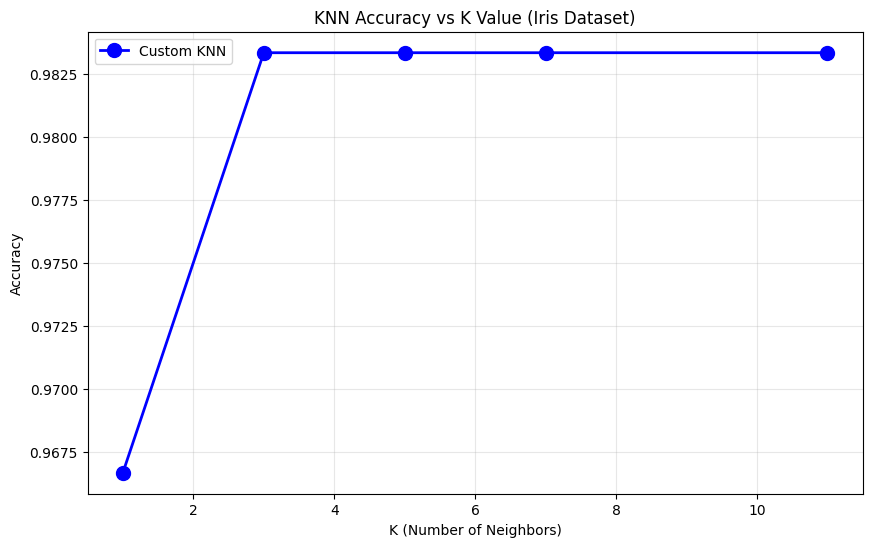


PART 2: COMPARISON WITH SKLEARN
K=1: Custom=0.9667, Sklearn=0.9667, Identical=True
K=3: Custom=0.9833, Sklearn=0.9833, Identical=True
K=5: Custom=0.9833, Sklearn=0.9833, Identical=True
K=7: Custom=0.9833, Sklearn=0.9833, Identical=True
K=11: Custom=0.9833, Sklearn=0.9833, Identical=True

All predictions identical? True

PART 3: DISTANCE METRICS COMPARISON

Distance Metrics Comparison on Iris Dataset:
--------------------------------------------------

Euclidean Distance:
  K=1: 0.9667
  K=3: 0.9833
  K=5: 0.9833
  K=7: 0.9833
  K=11: 0.9833

Manhattan Distance:
  K=1: 0.9500
  K=3: 0.9833
  K=5: 0.9833
  K=7: 0.9833
  K=11: 0.9833

Minkowski Distance:
  K=1: 0.9667
  K=3: 0.9833
  K=5: 0.9833
  K=7: 0.9833
  K=11: 0.9833


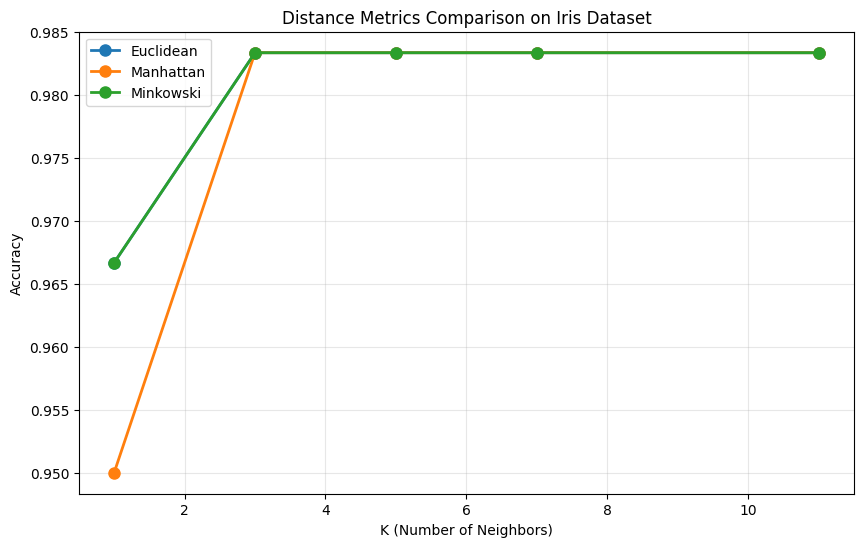


--------------------------------------------------
Minkowski Distance with different p values (K=5):
  p=1: Accuracy=0.9833
  p=2: Accuracy=0.9833
  p=3: Accuracy=0.9833
  p=4: Accuracy=0.9833
  p=5: Accuracy=0.9500


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris

class KNN:
    def __init__(self, k=3, distance_metric='euclidean', p=2):
        self.k = k
        self.distance_metric = distance_metric
        self.p = p
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
    
    def _euclidean_distance(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))
    
    def _manhattan_distance(self, x1, x2):
        return np.sum(np.abs(x1 - x2))
    
    def _minkowski_distance(self, x1, x2):
        return np.sum(np.abs(x1 - x2) ** self.p) ** (1/self.p)
    
    def _calculate_distance(self, x1, x2):
        if self.distance_metric == 'euclidean':
            return self._euclidean_distance(x1, x2)
        elif self.distance_metric == 'manhattan':
            return self._manhattan_distance(x1, x2)
        elif self.distance_metric == 'minkowski':
            return self._minkowski_distance(x1, x2)
    
    def predict(self, X):
        predictions = []
        for x in X:
            distances = [self._calculate_distance(x, x_train) for x_train in self.X_train]
            k_indices = np.argsort(distances)[:self.k]
            k_labels = self.y_train[k_indices]
            unique, counts = np.unique(k_labels, return_counts=True)
            predictions.append(unique[np.argmax(counts)])
        return np.array(predictions)
    
    def score(self, X, y):
        return np.mean(self.predict(X) == y)

# Load Iris dataset from sklearn (no data leakage)
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print("="*50)
print("PART 1: KNN FROM SCRATCH")
print("="*50)

# Split data
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Use a larger test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)

# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

k_values = [1, 3, 5, 7, 11]
custom_accuracies = []

print("Custom KNN Results:")
print("-" * 50)

for k in k_values:
    knn_custom = KNN(k=k)
    knn_custom.fit(X_train_scaled, y_train)
    acc_custom = knn_custom.score(X_test_scaled, y_test)
    custom_accuracies.append(acc_custom)
    print(f"K={k}: Custom={acc_custom:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(k_values, custom_accuracies, 'bo-', label='Custom KNN', linewidth=2, markersize=10)
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs K Value (Iris Dataset)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('knn_accuracy.png', dpi=150)
plt.show()

print("\n" + "="*50)
print("PART 2: COMPARISON WITH SKLEARN")
print("="*50)

sklearn_accuracies = []
identical_results = []

for k in k_values:
    # Custom KNN
    knn_custom = KNN(k=k)
    knn_custom.fit(X_train_scaled, y_train)
    y_pred_custom = knn_custom.predict(X_test_scaled)
    acc_custom = accuracy_score(y_test, y_pred_custom)
    
    # Sklearn KNN
    knn_sklearn = KNeighborsClassifier(n_neighbors=k)
    knn_sklearn.fit(X_train_scaled, y_train)
    y_pred_sklearn = knn_sklearn.predict(X_test_scaled)
    acc_sklearn = accuracy_score(y_test, y_pred_sklearn)
    
    identical = np.array_equal(y_pred_custom, y_pred_sklearn)
    identical_results.append(identical)
    
    print(f"K={k}: Custom={acc_custom:.4f}, Sklearn={acc_sklearn:.4f}, Identical={identical}")

# Check if all results are identical
all_identical = all(identical_results)
print(f"\nAll predictions identical? {all_identical}")

print("\n" + "="*50)
print("PART 3: DISTANCE METRICS COMPARISON")
print("="*50)

# Use Iris dataset for distance metric comparison
distance_metrics = ['euclidean', 'manhattan', 'minkowski']
k_values_for_metrics = [1, 3, 5, 7, 11]

print("\nDistance Metrics Comparison on Iris Dataset:")
print("-" * 50)

# Store results for plotting
results = {metric: [] for metric in distance_metrics}

for metric in distance_metrics:
    print(f"\n{metric.capitalize()} Distance:")
    for k in k_values_for_metrics:
        knn = KNN(k=k, distance_metric=metric)
        knn.fit(X_train_scaled, y_train)
        acc = knn.score(X_test_scaled, y_test)
        results[metric].append(acc)
        print(f"  K={k}: {acc:.4f}")

# Plot comparison of distance metrics
plt.figure(figsize=(10, 6))
for metric in distance_metrics:
    plt.plot(k_values_for_metrics, results[metric], 'o-', label=metric.capitalize(), linewidth=2, markersize=8)
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Accuracy')
plt.title('Distance Metrics Comparison on Iris Dataset')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('distance_metrics_comparison.png', dpi=150)
plt.show()

# Test different p values for Minkowski
print("\n" + "-" * 50)
print("Minkowski Distance with different p values (K=5):")
p_values = [1, 2, 3, 4, 5]
for p in p_values:
    knn = KNN(k=5, distance_metric='minkowski', p=p)
    knn.fit(X_train_scaled, y_train)
    acc = knn.score(X_test_scaled, y_test)
    print(f"  p={p}: Accuracy={acc:.4f}")